In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import sklearn
import numpy as np 

In [2]:
data = pd.read_csv('diabetes.csv')

In [3]:
data.shape

(768, 9)

In [4]:
data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<h5> quyidagi malumotlar hindiston qandli diabet va buyrak kasalliklari milliy instutidan olingan maqsad diagnostik olchovlar asosida bemorda DIABET BOR YOQLIGINI aniqlash

- Pregnancies: homilador bo'lish soni
- Glucose: glyukozaga test natijasi
- BloodPressure: diastolik qon bosimi (mm Hg)
- SkinThickness: Triceps teri burmasining qalinligi (mm)
- Insulin: 2 soatlik sarum insulini (mu U/ml)
- BMI: Tana massasi indeksi (vazn kg / (m bo'yi) ^ 2)
- DiabetesPedigreeFunction: diabetning naslchilik
- funktsiyasi
- Age: Yosh (yil)
- Outcome: Class (0 - diabet yo'q, 1 - diabet)

In [6]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## ⚔️prefect data

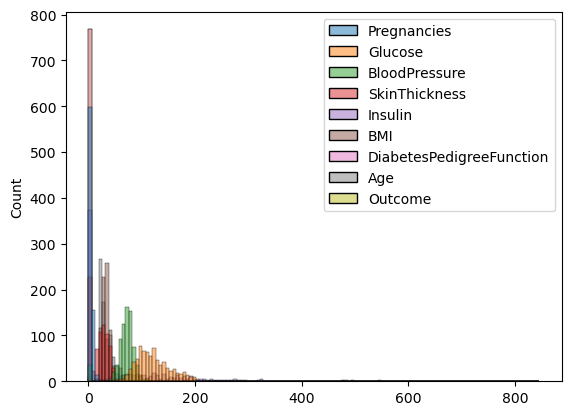

In [7]:
sns.histplot(data=data)
plt.show()

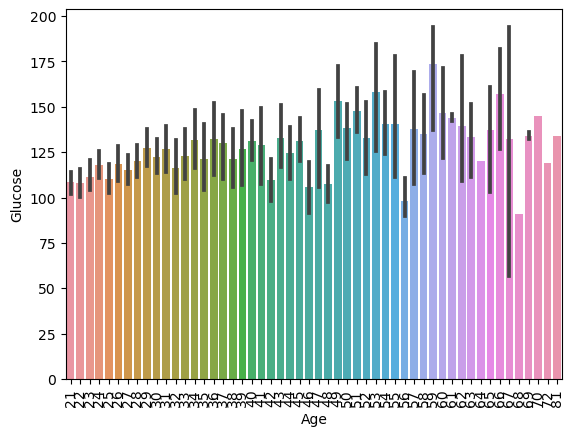

In [13]:
sns.barplot(x=data['Age'],y=data['Glucose'])
plt.xticks(rotation=90)
plt.show()

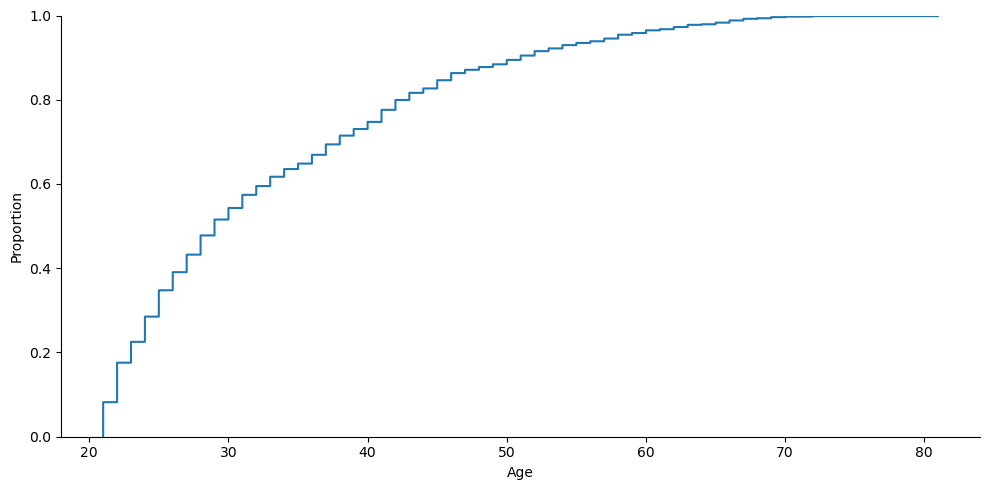

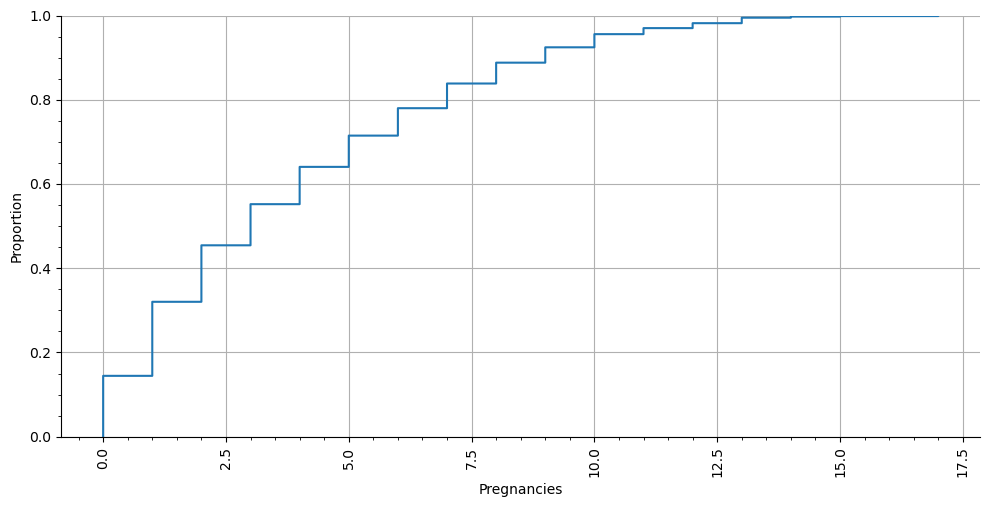

In [18]:
sns.displot(data=data, x='Age', kind='ecdf', height=5, aspect=2)
sns.displot(data=data, x='Pregnancies', kind='ecdf', height=5, aspect=2)
plt.xticks(rotation=90)
plt.grid()
plt.minorticks_on()
plt.show()

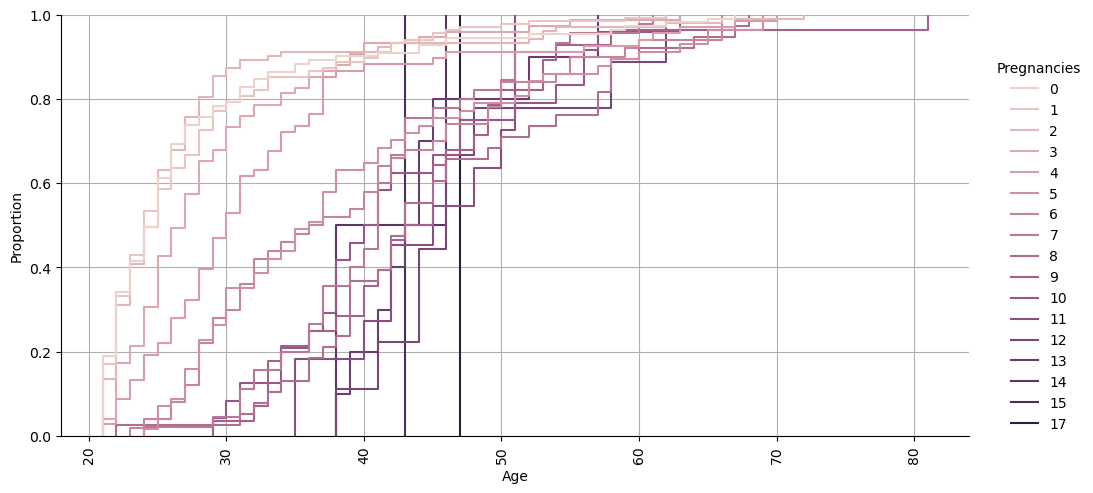

In [19]:
sns.displot(data=data, x="Age", hue="Pregnancies", kind="ecdf", height=5, aspect=2)
plt.xticks(rotation=90)
plt.grid()
plt.show()

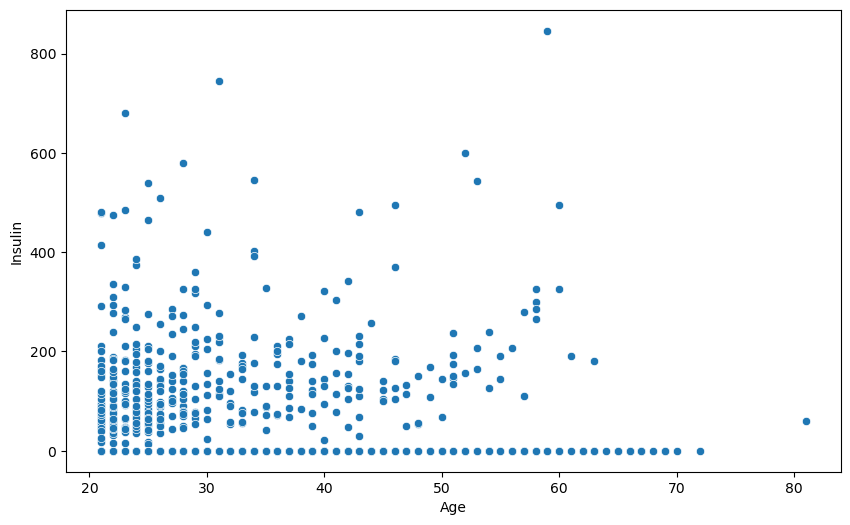

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=data, x='Age', y='Insulin')
plt.show()

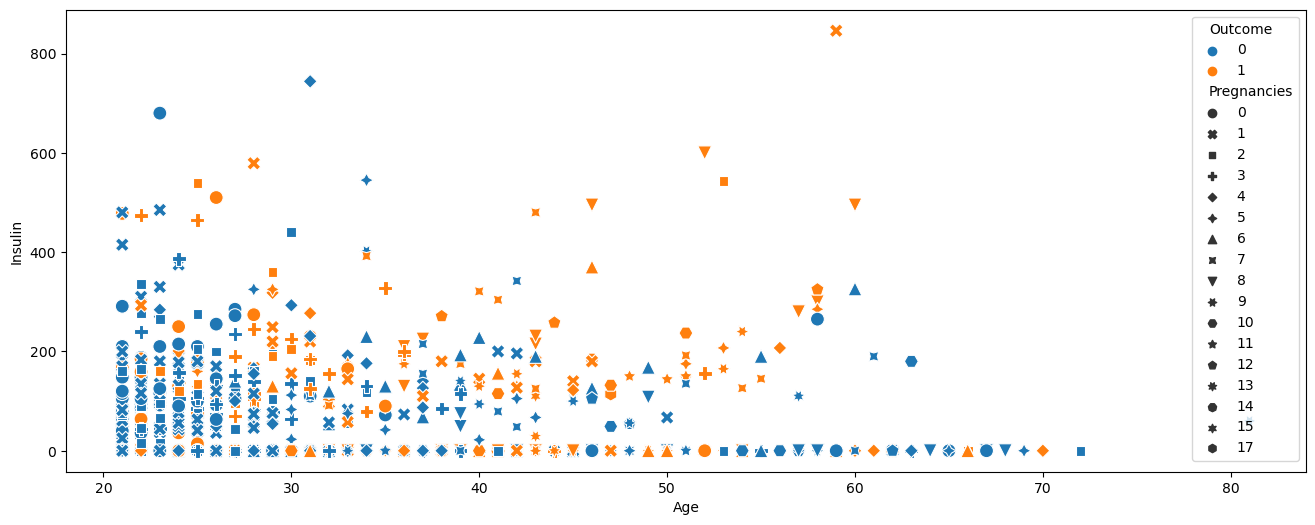

In [21]:
plt.figure(figsize=(16,6))
sns.scatterplot(data=data, x='Age', y='Insulin', hue='Outcome', style='Pregnancies', s=100)
plt.show()

<Axes: xlabel='Age', ylabel='Insulin'>

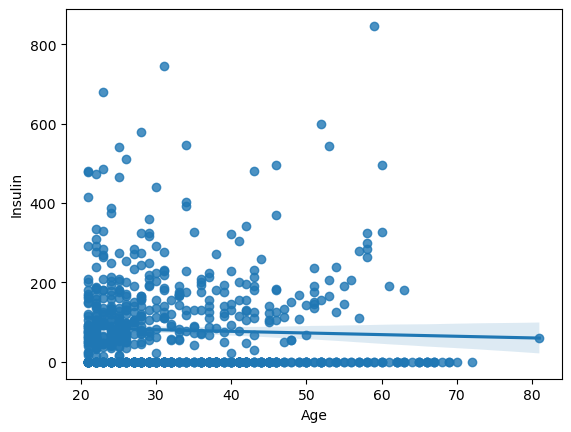

In [25]:
sns.regplot(data=data, x='Age', y='Insulin')

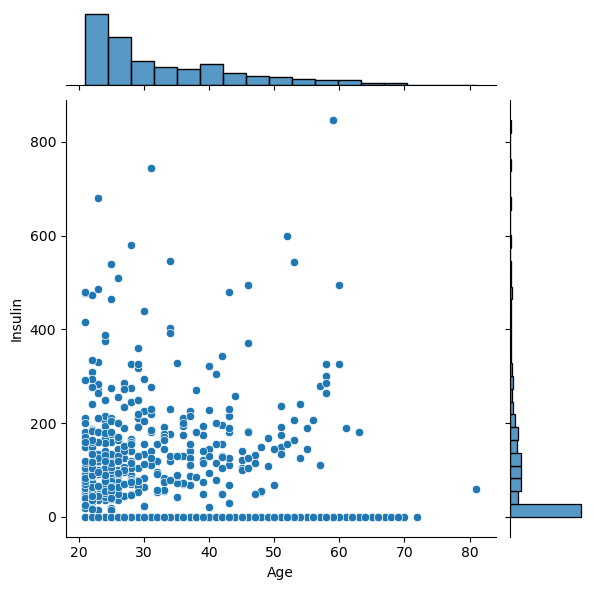

In [28]:
sns.jointplot(data=data, x='Age', y='Insulin')

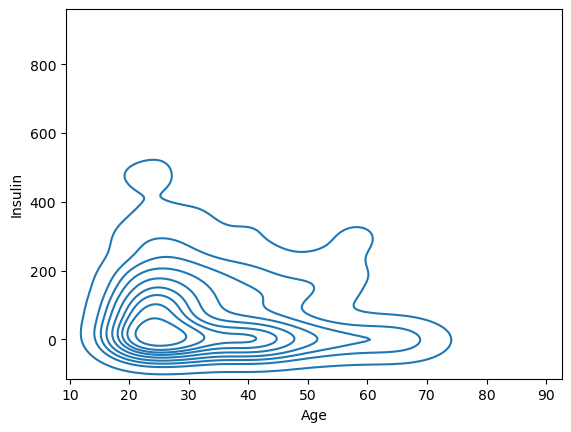

In [30]:
sns.kdeplot(data=data, x='Age', y='Insulin')
plt.show()

In [31]:
corr_data = data.corr().abs()
corr_data.style.background_gradient(cmap='coolwarm')

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,0.081672,0.073535,0.017683,0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,0.113970,0.074752
Insulin,0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,0.113970,0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


## machina learning

In [33]:
data.corrwith(data['Outcome']).abs().sort_values(ascending=False)

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
dtype: float64

In [36]:
x = data.drop('Outcome',axis=1)
y = data['Outcome']

In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(x)

In [39]:
from sklearn.model_selection import train_test_split 

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=16)

In [40]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [41]:
y_predic = knn.predict(x_test)

In [45]:
knn.score(x_test,y_test)

0.7727272727272727

In [42]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_neighbors': np.arange(1, 25)}

knn_gscv = GridSearchCV(knn, param_grid, cv=5)

knn_gscv.fit(X, y)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24])})

In [43]:
knn_gscv.cv_results_['rank_test_score']

array([24, 23, 15, 18, 22, 21, 17, 16, 20, 19, 14,  9,  4, 11,  3, 12,  1,
        6,  2,  8,  5, 10,  7, 13], dtype=int32)

In [44]:
knn_gscv.best_params_

{'n_neighbors': 17}

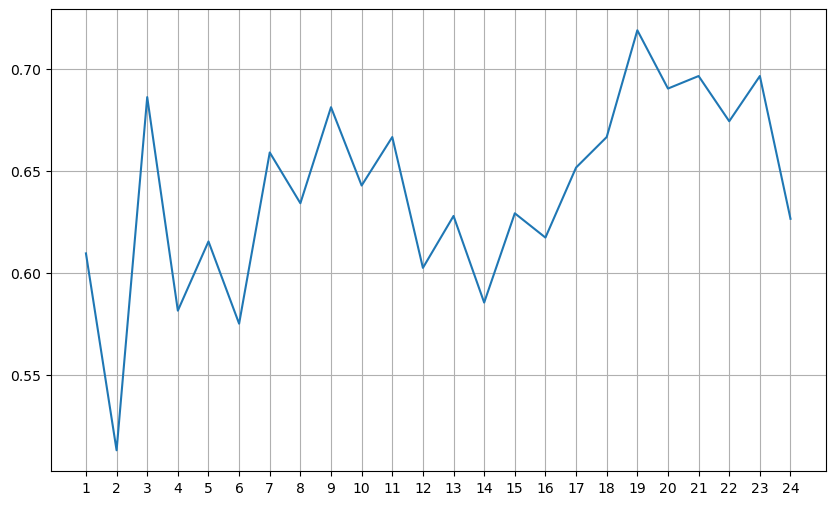

In [47]:
from sklearn.metrics import precision_score,recall_score,f1_score,accuracy_score
f1 = []
for k in range(1,25):
    knn = KNeighborsClassifier(n_neighbors=k) # k-ni qiymati
    knn.fit(x_train, y_train)
    y_predict = knn.predict(x_test)
    f1.append(f1_score(y_test, y_predict))

plt.figure(figsize=(10,6))
plt.plot(range(1,25),f1)
plt.xticks(range(1,25))
plt.grid()
plt.show()   

In [48]:
knn = KNeighborsClassifier(n_neighbors=19)
knn.fit(x_train,y_train)
knn.score(x_test,y_test)

0.8376623376623377

# Best k = 17 or 19

In [49]:
y_predic = knn.predict(x_test)

In [52]:
from sklearn.model_selection import cross_val_predict
predict = cross_val_predict(estimator=knn, X=X, y=y, cv=5)

from sklearn.metrics import classification_report

print(classification_report(y,predict))

              precision    recall  f1-score   support

           0       0.78      0.89      0.83       500
           1       0.72      0.53      0.61       268

    accuracy                           0.77       768
   macro avg       0.75      0.71      0.72       768
weighted avg       0.76      0.77      0.76       768



## deep learning

In [53]:
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential

In [54]:
model = keras.models.Sequential([
    keras.layers.Dense(512, activation="relu", input_shape=(x_train.shape[1],)),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(256,activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(128,activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation="softmax"),
])

Metal device set to: Apple M2

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB



In [55]:
print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               4608      
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_2 (Dense)             (None, 128)               32896     
                                                                 
 dropout_2 (Dropout)         (None, 128)               0         
                                                                 
 dense_3 (Dense)             (None, 64)                8

In [56]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics='accuracy')

In [61]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=50, batch_size=128)

Epoch 1/50
5/5 [==============================] - 0s 19ms/step - loss: 0.4956 - accuracy: 0.7557 - val_loss: 0.3964 - val_accuracy: 0.8117
Epoch 2/50
5/5 [==============================] - 0s 15ms/step - loss: 0.4906 - accuracy: 0.7818 - val_loss: 0.3872 - val_accuracy: 0.8052
Epoch 3/50
5/5 [==============================] - 0s 14ms/step - loss: 0.4734 - accuracy: 0.7801 - val_loss: 0.3898 - val_accuracy: 0.8052
Epoch 4/50
5/5 [==============================] - 0s 14ms/step - loss: 0.4984 - accuracy: 0.7736 - val_loss: 0.3892 - val_accuracy: 0.8052
Epoch 5/50
5/5 [==============================] - 0s 13ms/step - loss: 0.4644 - accuracy: 0.7720 - val_loss: 0.3942 - val_accuracy: 0.8052
Epoch 6/50
5/5 [==============================] - 0s 13ms/step - loss: 0.4715 - accuracy: 0.7687 - val_loss: 0.3933 - val_accuracy: 0.7922
Epoch 7/50
5/5 [==============================] - 0s 14ms/step - loss: 0.4601 - accuracy: 0.7899 - val_loss: 0.3897 - val_accuracy: 0.7922
Epoch 8/50
5/5 [===========

In [62]:
_, accuracy = model.evaluate(x_test, y_test, batch_size=128)

2/2 [==============================] - 0s 10ms/step - loss: 0.4309 - accuracy: 0.7922


In [63]:
print("Accuracy:",accuracy*100)

Accuracy: 79.22077775001526


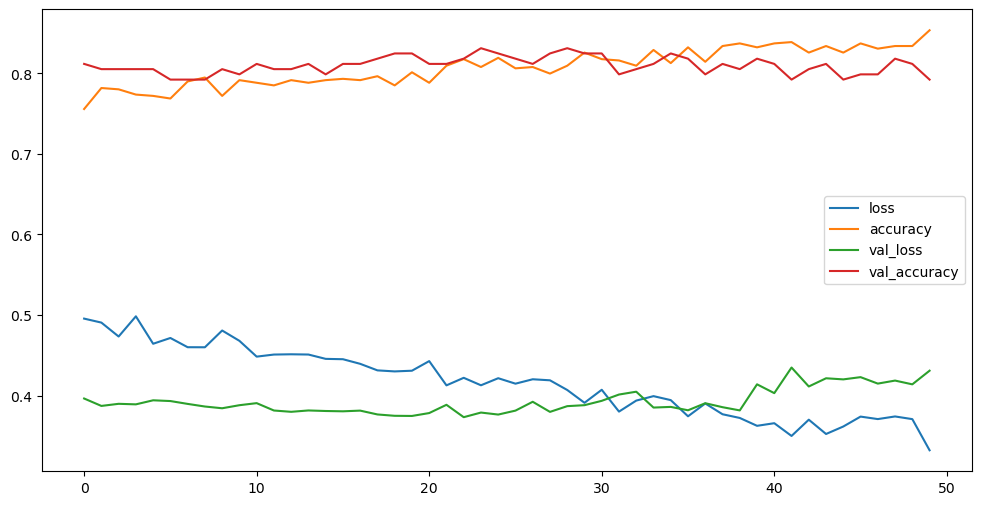

In [64]:
pd.DataFrame(history.history).plot(figsize=(12,6))
plt.show()